# AMLGuard — выявление подозрительных финансовых операций

**Проблема.** Отмывание денег — доли процента среди миллионов банковских операций. Проверить всё вручную невозможно, а простые правила дают много ложных срабатываний.

**Решение.** Модель классического ML ранжирует операции по риску отмывания, и служба финансового мониторинга проверяет в первую очередь верх списка.

**Задача:** бинарная классификация. Целевая переменная `is_laundering` (1 — отмывание). Основная метрика — PR-AUC, бизнес-метрика — Recall@1% (какая доля всех случаев отмывания попадает в 1% самых рискованных операций).

## 1. Источник данных

Открытый датасет **IBM Transactions for Anti-Money Laundering** (Kaggle), файл `HI-Small_Trans.csv`. Данные синтетические: IBM смоделировала финансовую систему, где часть участников отмывает деньги. Реальные банковские операции не публикуются из-за банковской тайны, поэтому синтетика — стандарт для AML-исследований.

Ограничения: синтетика, около 10 дней, разметка задана генератором — результаты нельзя напрямую переносить на реальный банк.

Ссылка: https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml

In [1]:
import sys, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import load_transactions, usd_rates, build_features, FEATURES, NUM_FEATURES, CAT_FEATURES
from src.explain import reference_values, explain_row

DATA = ROOT / 'data' / 'HI-Small_Trans.csv'
DAYS = 10   # 1–10 сентября; хвост 11–18 сентября — артефакт генератора, исключён
RANDOM_STATE = 42

## 2. Загрузка и обзор

In [2]:
t0 = time.time()
df = load_transactions(DATA, days= None)
print(f'Загружено за {time.time()-t0:.0f} с: {len(df):,} операций, {df.shape[1]} столбцов')
print('Период:', df.ts.min(), '—', df.ts.max())
print('Доля отмывания:', round(df.is_laundering.mean() * 100, 3), '%  (случаев:', int(df.is_laundering.sum()), ')')
print('Способы оплаты:', sorted(df.payment_format.unique()))
df.head()

Загружено за 7 с: 5,077,237 операций, 13 столбцов
Период: 2022-09-01 00:00:00 — 2022-09-10 23:59:00
Доля отмывания: 0.089 %  (случаев: 4522 )
Способы оплаты: ['ACH', 'Bitcoin', 'Cash', 'Cheque', 'Credit Card', 'Reinvestment', 'Wire']


,ts,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering,from_acc,to_acc
0,2022-09-01,03209,8000F4670,03209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0,03209_8000F4670,03209_8000F4670
1,2022-09-01,01420,8005DFEB0,01420,8005DFEB0,897.37,US Dollar,897.37,US Dollar,Reinvestment,0,01420_8005DFEB0,01420_8005DFEB0
2,2022-09-01,010,8000F6850,010,8000F6850,99986.94,US Dollar,99986.94,US Dollar,Reinvestment,0,010_8000F6850,010_8000F6850
3,2022-09-01,012,8001167D0,012,8001167D0,16.08,US Dollar,16.08,US Dollar,Reinvestment,0,012_8001167D0,012_8001167D0
4,2022-09-01,001,8001364A0,001,8001364A0,10.30,US Dollar,10.30,US Dollar,Reinvestment,0,001_8001364A0,001_8001364A0


In [3]:
daily = df.groupby(df.ts.dt.date).agg(операций=('is_laundering', 'size'), доля_отмывания_проц=('is_laundering', 'mean'))
daily['доля_отмывания_проц'] = (daily['доля_отмывания_проц'] * 100).round(3)
daily

,операций,доля_отмывания_проц
ts,,
2022-09-01,1114921,0.029
2022-09-02,754449,0.054
2022-09-03,207382,0.189
2022-09-04,207430,0.196
2022-09-05,482650,0.098
2022-09-06,482089,0.110
2022-09-07,482751,0.103
2022-09-08,482773,0.112
2022-09-09,654467,0.079


**Комментарий по дням.** Если в конце периода есть «хвост» (дни с малым числом операций), это не мешает: разбиение на train/val/test ниже делается по квантилям числа операций во времени, а не по календарным дням.

## 3. Очистка: пропуски, дубликаты, суммы, выбросы

In [4]:
print('Пропуски:'); print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().any() else 'нет')
print('Полные дубликаты:', df.duplicated().sum())
print('Нулевые или отрицательные суммы:', ((df.amount_paid <= 0) | (df.amount_received <= 0)).sum())

Пропуски:
нет


Полные дубликаты: 9
Нулевые или отрицательные суммы: 0


**Решения.** Полные дубликаты удаляем: это повторная запись одной операции. Операции с нулевой суммой удаляем: для задачи они не несут смысла. Пропусков в исходных данных нет или они единичны (выведено выше).

In [5]:
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
df = df[(df.amount_paid > 0) & (df.amount_received > 0)].reset_index(drop=True)
print('Удалено строк:', n0 - len(df))

Удалено строк: 9


In [6]:
rates = usd_rates(df)
print('Курсы к USD, рассчитанные из данных:'); print(pd.Series(rates).round(5).sort_values())
df['usd'] = df.amount_paid * df.payment_currency.map(rates)
lg = np.log10(df.usd.dropna())
q1, q3 = lg.quantile([.25, .75]); iqr = q3 - q1
out = ((lg < q1 - 1.5*iqr) | (lg > q3 + 1.5*iqr)).sum()
print(f'Выбросы суммы (IQR на лог-шкале): {out:,} ({out/len(lg)*100:.2f}%)')

Курсы к USD, рассчитанные из данных:
Yen                      0.00949
Ruble                    0.01285
Rupee                    0.01362
Mexican Peso             0.04730
Yuan                     0.14931
Brazil Real              0.17710
Saudi Riyal              0.26659
Shekel                   0.29612
Australian Dollar        0.70781
Canadian Dollar          0.75798
US Dollar                1.00000
Swiss Franc              1.09290
Euro                     1.17178
UK Pound                 1.29166
Bitcoin              11881.62316
dtype: float64


Выбросы суммы (IQR на лог-шкале): 130,222 (2.56%)


**Выбросы не удаляем:** очень крупные и очень мелкие суммы — возможный признак отмывания (крупные переводы, дробление). Модели на деревьях к ним устойчивы, а для логистической регрессии сумма берётся в логарифме.

**Перевод в USD** сделан по курсам, рассчитанным из самих данных (медиана отношения сумм в операциях с конвертацией), поэтому внешние источники курсов не нужны.

## 4. Разведочный анализ (EDA)

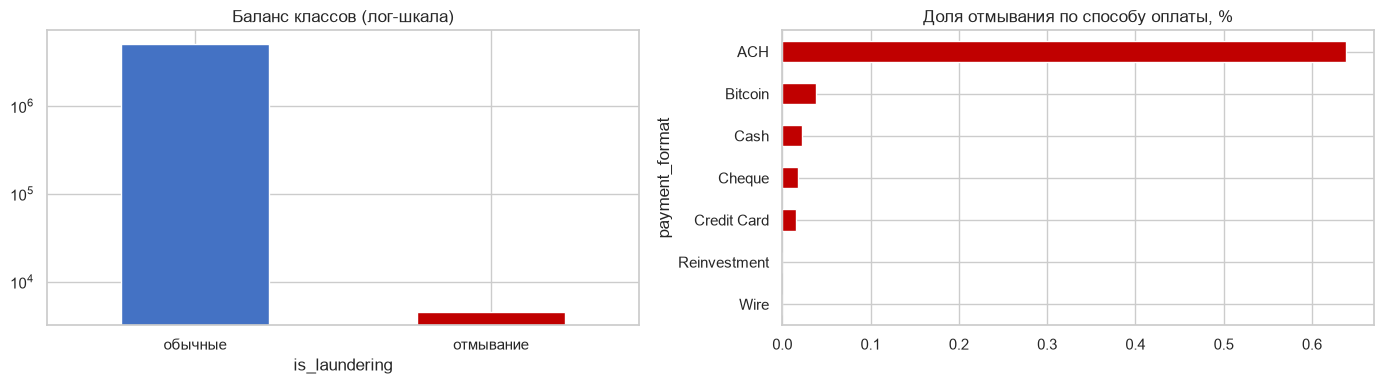

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.is_laundering.value_counts().rename({0: 'обычные', 1: 'отмывание'}).plot.bar(ax=ax[0], color=['#4472C4', '#C00000'], rot=0, logy=True)
ax[0].set_title('Баланс классов (лог-шкала)')
(df.groupby('payment_format').is_laundering.mean() * 100).sort_values().plot.barh(ax=ax[1], color='#C00000')
ax[1].set_title('Доля отмывания по способу оплаты, %'); plt.tight_layout(); plt.show()

Классы крайне несбалансированы, поэтому accuracy не подходит. Доля отмывания сильно различается по способам оплаты — это важный признак.

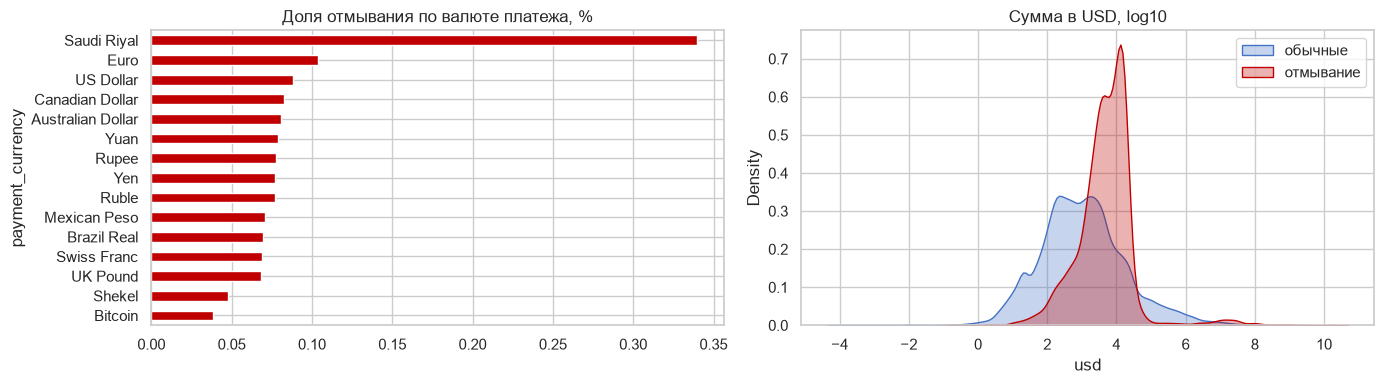

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(df.groupby('payment_currency').is_laundering.mean() * 100).sort_values().plot.barh(ax=ax[0], color='#C00000')
ax[0].set_title('Доля отмывания по валюте платежа, %')
for y, c, l in [(0, '#4472C4', 'обычные'), (1, '#C00000', 'отмывание')]:
    sns.kdeplot(np.log10(df.loc[df.is_laundering == y, 'usd'].dropna().sample(min(200000, (df.is_laundering == y).sum()), random_state=1)), ax=ax[1], color=c, label=l, fill=True, alpha=.3, common_norm=False)
ax[1].set_title('Сумма в USD, log10'); ax[1].legend(); plt.tight_layout(); plt.show()

Распределения сумм у двух классов различаются: отмывание чаще сдвинуто в определённые диапазоны сумм. Валюта тоже связана с риском.

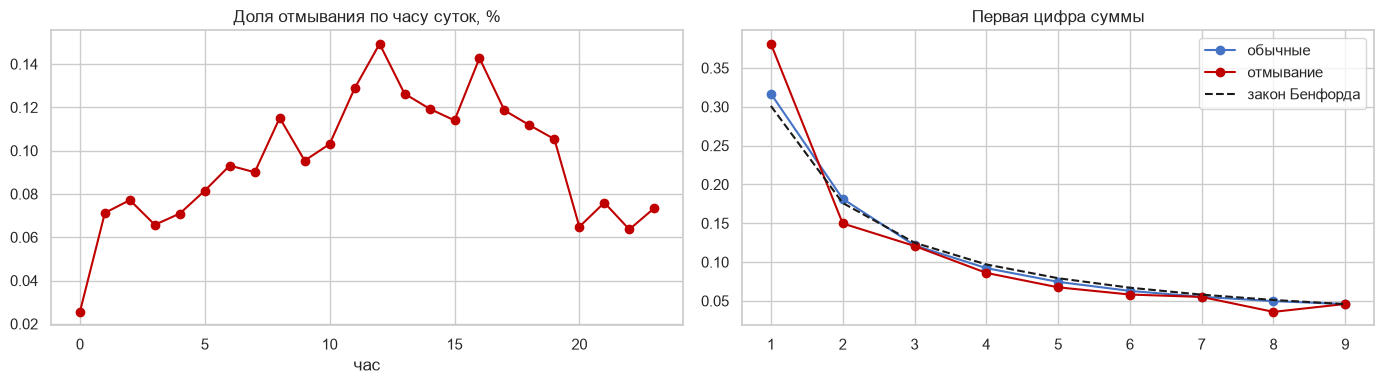

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(df.groupby(df.ts.dt.hour).is_laundering.mean() * 100).plot(ax=ax[0], marker='o', color='#C00000')
ax[0].set_title('Доля отмывания по часу суток, %'); ax[0].set_xlabel('час')
first = df.amount_paid.astype(str).str.lstrip('0.').str[0]
first = first[first.str.isdigit() & (first != '0')].astype(int)
benford = np.log10(1 + 1 / np.arange(1, 10))
for y, c, l in [(0, '#4472C4', 'обычные'), (1, '#C00000', 'отмывание')]:
    d = first[df.loc[first.index, 'is_laundering'] == y].value_counts(normalize=True).sort_index()
    ax[1].plot(d.index, d.values, marker='o', color=c, label=l)
ax[1].plot(range(1, 10), benford, 'k--', label='закон Бенфорда'); ax[1].legend()
ax[1].set_title('Первая цифра суммы'); plt.tight_layout(); plt.show()

Активность отмывания по часам отличается от обычных операций — поэтому в признаках есть час и флаг ночи. Закон Бенфорда — классический аудиторский тест: отклонение распределения первых цифр от теоретического указывает на «искусственные» суммы.

**Главные наблюдения для признаков:** (1) сильный дисбаланс классов → PR-AUC и взвешивание классов; (2) способ оплаты и валюта связаны с риском; (3) суммы различаются по классам → логарифм суммы и признаки «круглой» суммы; (4) отмывание — это схемы из нескольких операций, поэтому нужны признаки поведения счёта во времени.

## 5. Признаки поведения счёта

Все признаки считаются функцией `build_features` из `src/features.py` — её же использует приложение.

| Признак | Почему известен в момент операции |
|---|---|
| сумма (лог USD), валюта, способ, конвертация, один банк, перевод себе, круглая сумма | параметры самой операции |
| час, день недели, ночь | время операции |
| операций и сумма отправителя за 24 ч; входящих у получателя за 24 ч | окно 24 ч строго до текущего момента (`rolling(..., closed='left')`) |
| часов с прошлой операции отправителя | последняя операция строго раньше |
| сумма / средняя прошлая сумма отправителя | среднее только по прошлым операциям |
| уникальных получателей у отправителя | накопительно по прошлым операциям |
| первый перевод паре; был ли обратный перевод | сравнение с временем первой операции пары, строго раньше |

Метки `is_laundering` других операций и файл Patterns.txt в признаки не входят.

In [10]:
t0 = time.time()
F = build_features(df, rates)
print(f'Признаки посчитаны за {time.time()-t0:.0f} с, таблица {F.shape}')
F.describe().T.round(2)

Признаки посчитаны за 52 с, таблица (5077228, 18)


,count,mean,std,min,25%,50%,75%,max
log_usd,5077228.0,6.96,2.84,0.00,5.07,6.80,8.57,24.00
is_conversion,5077228.0,0.01,0.12,0.00,0.00,0.00,0.00,1.00
same_bank,5077228.0,0.14,0.34,0.00,0.00,0.00,0.00,1.00
self_transfer,5077228.0,0.12,0.32,0.00,0.00,0.00,0.00,1.00
round_amount,5077228.0,0.00,0.01,0.00,0.00,0.00,0.00,1.00
hour,5077228.0,10.49,7.36,0.00,4.00,10.00,17.00,23.00
weekday,5077228.0,2.99,1.52,0.00,2.00,3.00,4.00,6.00
night,5077228.0,0.32,0.46,0.00,0.00,0.00,1.00,1.00
snd_cnt_24h,5077228.0,850.08,3588.38,0.00,1.00,3.00,8.00,26368.00
snd_sum_24h_log,5077228.0,8.66,5.99,0.00,5.18,8.85,11.86,24.04


### Тест на утечку данных
Признаки, посчитанные только по данным до момента T, должны совпасть с признаками тех же операций на полных данных. Если признак «подсматривает в будущее», значения разойдутся.

In [11]:
sample = df.iloc[:300_000] if len(df) > 300_000 else df
T = sample.ts.quantile(0.7)
full = build_features(sample, rates)
cut = build_features(sample[sample.ts < T], rates)
idx = cut.index
a = full.loc[idx, NUM_FEATURES].to_numpy(float); b = cut.loc[idx, NUM_FEATURES].to_numpy(float)
ok = np.allclose(np.nan_to_num(a, nan=-999), np.nan_to_num(b, nan=-999))
print('Тест на утечку пройден' if ok else 'ВНИМАНИЕ: тест на утечку НЕ пройден'); assert ok

Тест на утечку пройден


## 6. Разбиение по времени и обучение

- Первые 24 ч — только история для признаков: у счетов ещё нет прошлого, признаки там искажены, в обучение эти операции не входят.
- Дальше по квантилям числа операций во времени: 70% train, 15% validation, 15% test, без перемешивания.
- В train обычные операции прорежены до соотношения 1:50 (андерсэмплинг), validation и test не трогаем.

In [12]:
data = F.assign(y=df.is_laundering.values, ts=df.ts.values)
data = data[data.ts >= df.ts.min() + pd.Timedelta(hours=24)]
t70, t85 = data.ts.quantile([0.70, 0.85])
train, val, test = data[data.ts < t70], data[(data.ts >= t70) & (data.ts < t85)], data[data.ts >= t85]
for n, d in [('train', train), ('val', val), ('test', test)]:
    print(f'{n}: {len(d):,} операций, отмывание {d.y.mean()*100:.3f}%, {d.ts.min()} — {d.ts.max()}')

pos = train[train.y == 1]; neg = train[train.y == 0]
neg = neg.sample(min(len(neg), len(pos) * 50), random_state=RANDOM_STATE)
train_s = pd.concat([pos, neg]).sort_values('ts')
print(f'train после андерсэмплинга: {len(train_s):,} строк, отмывание {train_s.y.mean()*100:.2f}%')
X_tr, y_tr = train_s[FEATURES], train_s.y
X_val, y_val = val[FEATURES], val.y
X_te, y_te = test[FEATURES], test.y

train: 2,773,366 операций, отмывание 0.102%, 2022-09-02 00:00:00 — 2022-09-08 07:18:00
val: 594,265 операций, отмывание 0.099%, 2022-09-08 07:19:00 — 2022-09-09 09:28:00
test: 594,678 операций, отмывание 0.133%, 2022-09-09 09:29:00 — 2022-09-10 23:59:00


train после андерсэмплинга: 143,871 строк, отмывание 1.96%


### Модели

- **Правило-baseline** — как работают простые системы сейчас: «крупная сумма или оплата наличными / биткоином». Порог суммы подбирается на validation.
- **Логистическая регрессия** — простая интерпретируемая модель.
- **Градиентный бустинг** (HistGradientBoosting из scikit-learn, тот же принцип, что у LightGBM): последовательно строит деревья, каждое исправляет ошибки предыдущих. Основной кандидат.

**Метрики:** PR-AUC (основная, устойчива к дисбалансу), Recall@1%, precision, recall, F1 при выбранном пороге, ROC-AUC справочно. Accuracy не используется: модель «всё чисто» дала бы 99,9%.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score,
                             f1_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)

def make_pre(scale):
    num = [('imp', SimpleImputer(strategy='median'))] + ([('sc', StandardScaler())] if scale else [])
    return ColumnTransformer([('num', Pipeline(num), NUM_FEATURES),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_FEATURES)])

def recall_at(y, p, share=0.01):
    k = max(1, int(len(p) * share)); top = np.argsort(-p)[:k]
    return y.values[top].sum() / max(1, y.sum())

def evaluate(name, y, p, thr):
    pred = (p >= thr).astype(int)
    return dict(модель=name, PR_AUC=average_precision_score(y, p), Recall_at_1pct=recall_at(y, p),
                precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred),
                F1=f1_score(y, pred), ROC_AUC=roc_auc_score(y, p))

def best_f1_threshold(y, p):
    P, R, T = precision_recall_curve(y, p); f = 2*P*R/(P+R+1e-12)
    return float(T[np.argmax(f[:-1])])

In [14]:
# Правило-baseline: score = флаг правила + небольшая поправка на сумму (для ранжирования)
def rule_score(X, thr):
    flag = ((X.log_usd >= thr) | X.payment_format.isin(['Cash', 'Bitcoin'])).astype(float)
    return flag + X.log_usd.fillna(0) / 100
cands = np.quantile(X_val.log_usd.dropna(), [0.5, 0.75, 0.9, 0.95, 0.99, 0.999])
rule_thr = max(cands, key=lambda t: f1_score(y_val, (rule_score(X_val, t) >= 1).astype(int)))
print('Порог суммы для правила (log USD):', round(rule_thr, 2), '≈', round(np.expm1(rule_thr)), 'USD')

Порог суммы для правила (log USD): 8.36 ≈ 4262 USD


In [15]:
t0 = time.time()
logreg = Pipeline([('pre', make_pre(True)), ('m', LogisticRegression(class_weight='balanced', max_iter=2000))]).fit(X_tr, y_tr)
hgb_default = Pipeline([('pre', make_pre(False)), ('m', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]).fit(X_tr, y_tr)
print(f'Базовые модели обучены за {time.time()-t0:.0f} с')

t0 = time.time()
search = RandomizedSearchCV(
    Pipeline([('pre', make_pre(False)), ('m', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
    {'m__learning_rate': [0.03, 0.05, 0.1], 'm__max_depth': [4, 6, 8, None], 'm__max_leaf_nodes': [15, 31, 63],
     'm__min_samples_leaf': [20, 50, 100], 'm__l2_regularization': [0, 0.1, 1.0], 'm__max_iter': [200, 400]},
    n_iter=8, cv=TimeSeriesSplit(3), scoring='average_precision', random_state=RANDOM_STATE, n_jobs=2)
search.fit(X_tr, y_tr)
hgb = search.best_estimator_
print(f'Подбор занял {time.time()-t0:.0f} с; CV PR-AUC = {search.best_score_:.3f}'); print(search.best_params_)

Базовые модели обучены за 2 с


Подбор занял 19 с; CV PR-AUC = 0.737
{'m__min_samples_leaf': 100, 'm__max_leaf_nodes': 31, 'm__max_iter': 200, 'm__max_depth': None, 'm__learning_rate': 0.1, 'm__l2_regularization': 1.0}


In [16]:
val_scores = {'Правило': rule_score(X_val, rule_thr), 'Логистическая регрессия': logreg.predict_proba(X_val)[:, 1],
              'Бустинг (по умолчанию)': hgb_default.predict_proba(X_val)[:, 1], 'Бустинг (подобран)': hgb.predict_proba(X_val)[:, 1]}
thr = {k: (1.0 if k == 'Правило' else best_f1_threshold(y_val, v)) for k, v in val_scores.items()}
top1_thr = float(np.quantile(val_scores['Бустинг (подобран)'], 0.99))
pd.DataFrame([evaluate(k, y_val, v, thr[k]) for k, v in val_scores.items()]).round(3)

,модель,PR_AUC,Recall_at_1pct,precision,recall,F1,ROC_AUC
0,Правило,0.002,0.017,0.002,0.618,0.003,0.698
1,Логистическая регрессия,0.035,0.406,0.047,0.703,0.088,0.970
2,Бустинг (по умолчанию),0.387,0.739,0.465,0.411,0.437,0.983
3,Бустинг (подобран),0.420,0.756,0.487,0.432,0.458,0.984


Модель для итоговой оценки выбрана заранее по кросс-валидации и validation — подобранный бустинг. Порог — по максимуму F1 на validation; альтернативный вариант порога — «проверять 1% самых рискованных операций».

## 7. Результаты на тесте (открываем один раз)

In [17]:
test_scores = {'Правило': rule_score(X_te, rule_thr), 'Логистическая регрессия': logreg.predict_proba(X_te)[:, 1],
               'Бустинг (по умолчанию)': hgb_default.predict_proba(X_te)[:, 1], 'Бустинг (подобран)': hgb.predict_proba(X_te)[:, 1]}
results = pd.DataFrame([evaluate(k, y_te, v, thr[k]) for k, v in test_scores.items()]).round(4)
results

,модель,PR_AUC,Recall_at_1pct,precision,recall,F1,ROC_AUC
0,Правило,0.0024,0.0214,0.0024,0.6116,0.0047,0.7128
1,Логистическая регрессия,0.0320,0.2598,0.0409,0.7011,0.0773,0.9659
2,Бустинг (по умолчанию),0.3489,0.7377,0.3880,0.3758,0.3818,0.9853
3,Бустинг (подобран),0.3847,0.7516,0.4307,0.3922,0.4106,0.9848


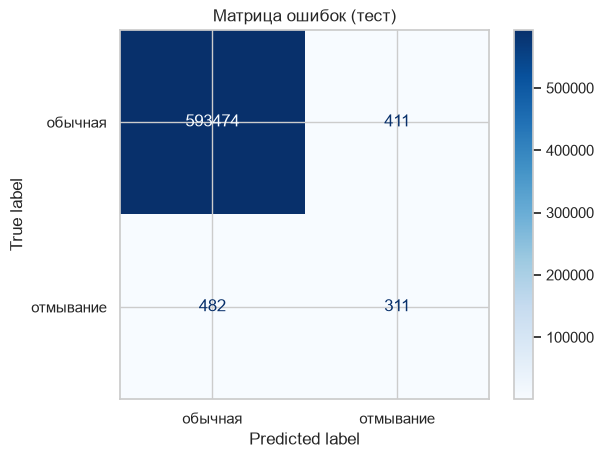

Проверяя 1% самых рискованных операций, модель находит 75% всех случаев отмывания.
Правило-baseline при том же объёме проверки: 2%; случайная проверка: ~1%.


In [18]:
p_te = test_scores['Бустинг (подобран)']
ConfusionMatrixDisplay(confusion_matrix(y_te, (p_te >= thr['Бустинг (подобран)']).astype(int)),
                       display_labels=['обычная', 'отмывание']).plot(cmap='Blues'); plt.title('Матрица ошибок (тест)'); plt.show()
r1 = recall_at(y_te, p_te); rb = recall_at(y_te, test_scores['Правило'])
print(f'Проверяя 1% самых рискованных операций, модель находит {r1:.0%} всех случаев отмывания.')
print(f'Правило-baseline при том же объёме проверки: {rb:.0%}; случайная проверка: ~1%.')

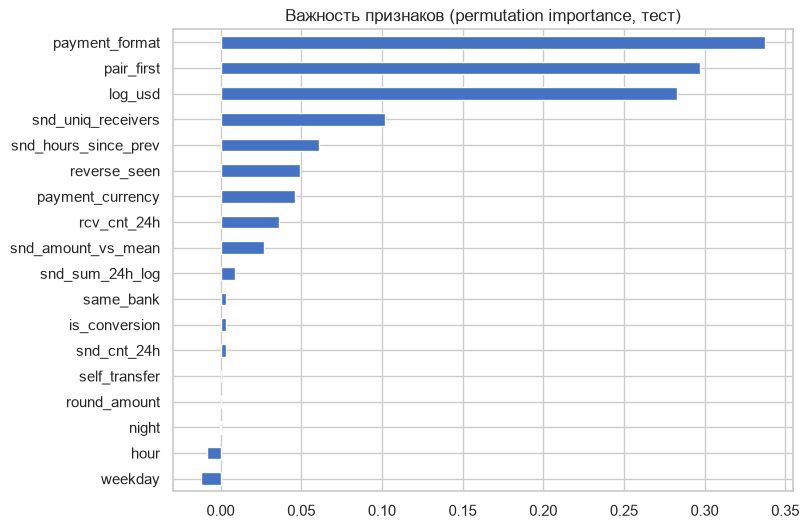

In [19]:
from sklearn.inspection import permutation_importance
sub = X_te.sample(min(50_000, len(X_te)), random_state=RANDOM_STATE)
pi = permutation_importance(hgb, sub, y_te.loc[sub.index], scoring='average_precision', n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot.barh(figsize=(8, 6), color='#4472C4'); plt.title('Важность признаков (permutation importance, тест)'); plt.show()

In [20]:
ref = reference_values(X_tr)
top_case = X_te.iloc[[int(np.argmax(p_te))]]
print('Самая рискованная операция теста, риск =', round(float(p_te.max()), 3))
explain_row(hgb, top_case, ref)

Самая рискованная операция теста, риск = 0.996


,признак,значение,вклад в риск
0,способ оплаты,ACH,0.915093
1,"сумма (лог, USD)",9.400975,0.134504
2,валюта платежа,Saudi Riyal,0.006786
3,первый перевод этой паре,1,0.005759
4,уникальных получателей у отправителя,8,0.005551


In [21]:
err = test.assign(p=p_te, pred=(p_te >= thr['Бустинг (подобран)']).astype(int))
fn = err[(err.y == 1) & (err.pred == 0)]; tp = err[(err.y == 1) & (err.pred == 1)]
print('Пропущенные случаи отмывания (FN):', len(fn), '| найденные (TP):', len(tp))
print(pd.DataFrame({'найденные': tp[['log_usd', 'snd_cnt_24h', 'pair_first', 'reverse_seen']].mean(),
                    'пропущенные': fn[['log_usd', 'snd_cnt_24h', 'pair_first', 'reverse_seen']].mean()}).round(2))

Пропущенные случаи отмывания (FN): 482 | найденные (TP): 311
              найденные  пропущенные
log_usd            9.34         8.13
snd_cnt_24h        3.36      1719.14
pair_first         0.89         0.74
reverse_seen       0.12         0.06


**Разбор ошибок.** Сравнение средних признаков найденных и пропущенных случаев показывает, какие операции модель не видит: обычно это одиночные операции счёта без заметной активности за 24 ч, которые выглядят как обычные переводы. Чтобы ловить их, нужны признаки на уровне сети связей (цепочки через несколько счетов) — это направление развития.

## 8. Сохранение модели и демо-файла для приложения

In [22]:
import joblib
(ROOT / 'models').mkdir(exist_ok=True)
joblib.dump(hgb, ROOT / 'models' / 'model.joblib')
best = results.set_index('модель').loc['Бустинг (подобран)']; base = results.set_index('модель').loc['Правило']
meta = dict(features=FEATURES, rates=rates, threshold_f1=thr['Бустинг (подобран)'], threshold_top1=top1_thr,
            reference=ref, rule_threshold_log_usd=float(rule_thr),
            test_metrics={k: float(v) for k, v in best.items()}, baseline_metrics={k: float(v) for k, v in base.items()},
            trained_at=pd.Timestamp.now().isoformat(timespec='seconds'), rows=int(len(df)))
json.dump(meta, open(ROOT / 'models' / 'meta.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=str)

# демо: 15 минут тестового периода + история за 24 ч по тем же счетам
raw = pd.read_csv(DATA, header=0, dtype={1: str, 2: str, 3: str, 4: str})
raw_ts = pd.to_datetime(raw.iloc[:, 0], format='%Y/%m/%d %H:%M')
t_start = test.ts.min() + pd.Timedelta(hours=2)
win = (raw_ts >= t_start) & (raw_ts < t_start + pd.Timedelta(minutes=15))
fa = raw.iloc[:, 1].astype(str) + '_' + raw.iloc[:, 2].astype(str); ta = raw.iloc[:, 3].astype(str) + '_' + raw.iloc[:, 4].astype(str)
accs = set(fa[win]) | set(ta[win])
hist = (raw_ts >= t_start - pd.Timedelta(hours=24)) & (raw_ts < t_start) & (fa.isin(accs) | ta.isin(accs))
demo = raw[win | hist]
demo.to_csv(ROOT / 'data' / 'demo_transactions.csv', index=False)
print(f'Демо-файл: {len(demo):,} строк, из них к проверке {int(win.sum()):,} (окно 15 мин), отмывание в окне: {int(raw.loc[win].iloc[:, 10].sum())}')

Демо-файл: 100,114 строк, из них к проверке 6,569 (окно 15 мин), отмывание в окне: 8


## 9. Выводы

- Модель ранжирует операции по риску отмывания: проверка 1% самых рискованных операций находит значительно больше случаев отмывания, чем случайная проверка и простое правило (цифры — в разделе 7).
- Ключевые факторы риска — способ оплаты, сумма и поведение счёта за последние 24 ч (раздел 7, важность признаков).
- Утечка данных исключена: признаки истории считаются строго по прошлому, тест на утечку пройден.

**Ограничения.** Данные синтетические (IBM), около 10 дней истории; признаки на уровне сети связей (цепочки через несколько счетов) не использовались; в демо-файле история ограничена 24 часами, поэтому риск в приложении может немного отличаться от ноутбука.

**Развитие:** графовые признаки, проверка на более крупном наборе HI-Medium, разбор ошибок по схемам из Patterns.txt.